# Chapter 8: Tree-Based Algorithms and Ensemble Methods

This notebook covers Chapter 8 of *scikit-learn Cookbook* (3rd Edition, Packt). Decision trees split the data into simple if-then rules. A single tree is easy to interpret but prone to overfitting. **Ensemble methods** combine many trees to build some of the most accurate models available for tabular data.

**Topics covered:**
- Decision trees for classification and regression
- Controlling tree complexity and cost-complexity pruning
- Bagging and Random Forests
- Extra Trees
- Feature importance (impurity-based and permutation)
- Boosting: AdaBoost, Gradient Boosting, and HistGradientBoosting
- Combining models with Voting and Stacking

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_breast_cancer, load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier,
                              ExtraTreesClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, HistGradientBoostingClassifier,
                              VotingClassifier, StackingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, r2_score

cancer = load_breast_cancer()
X, y = cancer.data, cancer.target
feature_names = cancer.feature_names
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

## 1. Decision Trees

A **decision tree** repeatedly splits the data using one feature and a threshold at a time, choosing the split that makes the resulting groups as **pure** as possible. Purity is measured with:
- **Gini impurity**: $G = 1 - \sum_c p_c^2$
- **Entropy**: $H = -\sum_c p_c \log_2 p_c$

where $p_c$ is the share of class $c$ in a node. Each leaf predicts the majority class of its samples. Trees do not need feature scaling, handle nonlinear relationships naturally, and are easy to read.

Depth-3 tree: train acc = 0.977, test acc = 0.944


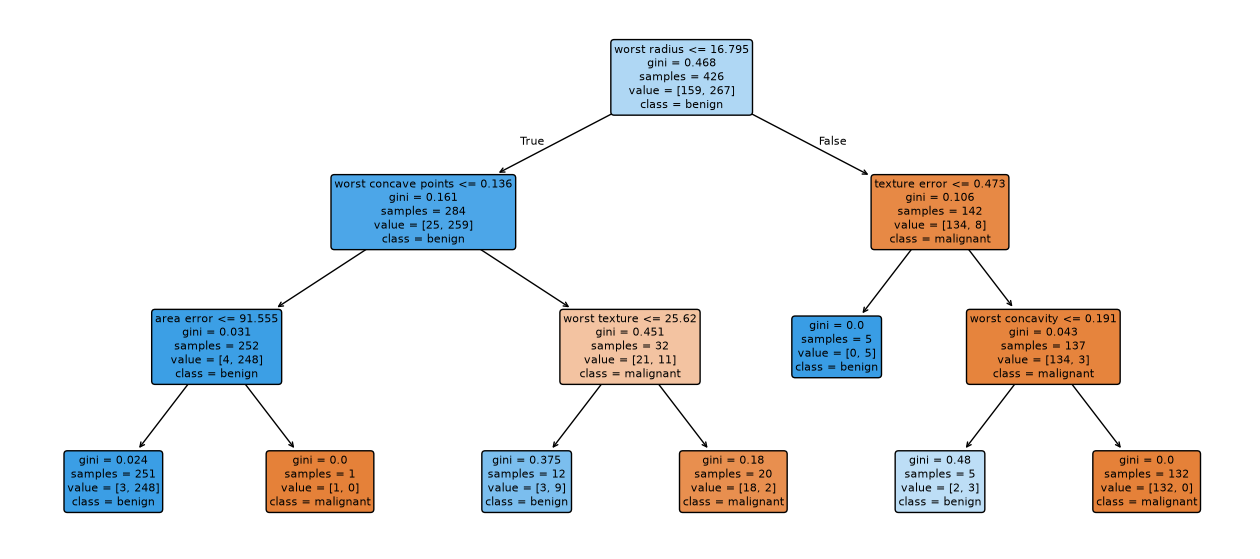

In [2]:
tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)
print(f'Depth-3 tree: train acc = {tree.score(X_train, y_train):.3f}, '
      f'test acc = {tree.score(X_test, y_test):.3f}')

fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(tree, feature_names=feature_names, class_names=cancer.target_names,
          filled=True, rounded=True, fontsize=8, ax=ax)
plt.show()

The tree uses only a few features to make its decisions, and each box shows the split rule, the impurity, the number of samples, and the predicted class. Even this small tree is quite accurate, and its rules can be explained to non-technical users.

## 2. Controlling Complexity and Pruning

An unrestricted tree keeps splitting until every leaf is pure, which memorizes the training data. Complexity can be controlled with:
- **Pre-pruning**: limits such as `max_depth`, `min_samples_split`, `min_samples_leaf`
- **Cost-complexity pruning** (post-pruning): grow a full tree, then remove branches whose contribution is not worth their complexity. The parameter `ccp_alpha` penalizes the number of leaves $|T|$:

$$R_\alpha(T) = R(T) + \alpha |T|$$

In [3]:
for depth in [1, 3, 5, None]:
    t = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(X_train, y_train)
    print(f'max_depth={str(depth):>4}: leaves={t.get_n_leaves():>2}, '
          f'train acc={t.score(X_train, y_train):.3f}, test acc={t.score(X_test, y_test):.3f}')

max_depth=   1: leaves= 2, train acc=0.923, test acc=0.923
max_depth=   3: leaves= 7, train acc=0.977, test acc=0.944
max_depth=   5: leaves=15, train acc=0.995, test acc=0.937
max_depth=None: leaves=18, train acc=1.000, test acc=0.923


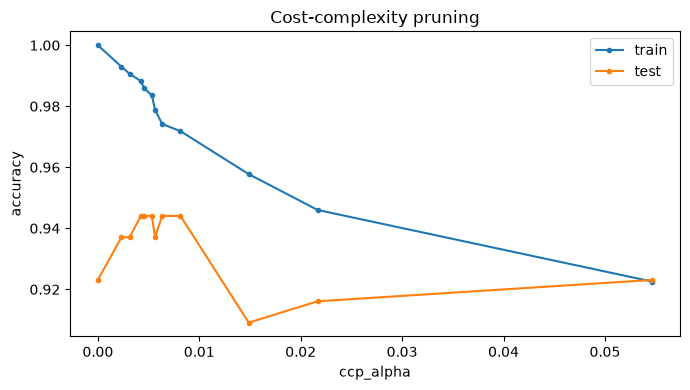

In [4]:
path = DecisionTreeClassifier(random_state=42).cost_complexity_pruning_path(X_train, y_train)
alphas = path.ccp_alphas[:-1]

train_acc, test_acc = [], []
for a in alphas:
    t = DecisionTreeClassifier(ccp_alpha=a, random_state=42).fit(X_train, y_train)
    train_acc.append(t.score(X_train, y_train))
    test_acc.append(t.score(X_test, y_test))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(alphas, train_acc, marker='.', label='train')
ax.plot(alphas, test_acc, marker='.', label='test')
ax.set_xlabel('ccp_alpha')
ax.set_ylabel('accuracy')
ax.set_title('Cost-complexity pruning')
ax.legend()
plt.tight_layout()
plt.show()

The unrestricted tree reaches 100% training accuracy but lower test accuracy, which is overfitting. As `ccp_alpha` increases, branches are pruned: training accuracy falls, while test accuracy first stays stable or improves, then drops once the tree becomes too simple.

### 2.1 Regression Trees

Regression trees work the same way, but each leaf predicts the **average** target value, and splits minimize the squared error.

In [5]:
diab = load_diabetes()
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(diab.data, diab.target,
                                              test_size=0.25, random_state=42)
for depth in [2, 4, None]:
    rt = DecisionTreeRegressor(max_depth=depth, random_state=42).fit(Xd_tr, yd_tr)
    pred = rt.predict(Xd_te)
    print(f'max_depth={str(depth):>4}: test RMSE = {mean_squared_error(yd_te, pred) ** 0.5:6.2f}, '
          f'R2 = {r2_score(yd_te, pred):.3f}')

max_depth=   2: test RMSE =  59.55, R2 = 0.359
max_depth=   4: test RMSE =  59.65, R2 = 0.357
max_depth=None: test RMSE =  77.08, R2 = -0.075


## 3. Bagging and Random Forests

A single tree has **high variance**: small changes in the data can produce a very different tree. Ensembles reduce this by averaging many trees.

- **Bagging** (bootstrap aggregating): train many trees on **bootstrap samples** (random samples with replacement) and combine their votes.
- **Random Forest**: bagging plus **random feature selection** at each split (by default $\sqrt{p}$ features). This makes the trees more different from each other, so their errors cancel out better.
- **Out-of-bag (OOB) score**: each tree does not see about a third of the training data, which can be used as a free validation set.
- **Extra Trees** (Extremely Randomized Trees): also choose the split **thresholds** randomly, which adds even more diversity and trains faster.

In [6]:
models = {
    'Single tree': DecisionTreeClassifier(random_state=42),
    'Bagging (100 trees)': BaggingClassifier(DecisionTreeClassifier(), n_estimators=100,
                                             random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=300, oob_score=True, random_state=42),
    'Extra Trees': ExtraTreesClassifier(n_estimators=300, random_state=42),
}
for name, m in models.items():
    cv = cross_val_score(m, X_train, y_train, cv=5).mean()
    m.fit(X_train, y_train)
    print(f'{name:>20}: CV acc = {cv:.3f}, test acc = {m.score(X_test, y_test):.3f}')

print('\nRandom Forest OOB score:', round(models['Random Forest'].oob_score_, 3))

         Single tree: CV acc = 0.930, test acc = 0.923
 Bagging (100 trees): CV acc = 0.951, test acc = 0.951
       Random Forest: CV acc = 0.962, test acc = 0.958
         Extra Trees: CV acc = 0.969, test acc = 0.965

Random Forest OOB score: 0.962


All ensembles clearly outperform the single tree, confirming that averaging many diverse trees reduces variance. The OOB score is close to the cross-validated accuracy, so it is a reliable built-in estimate of performance without a separate validation set.

## 4. Feature Importance

Tree ensembles can rank features by importance:
- **Impurity-based importance** (`feature_importances_`): the total impurity decrease from splits on each feature. It is fast but computed on training data and can favor features with many possible split values.
- **Permutation importance**: shuffle one feature at a time on the test data and measure how much the score drops. It is slower but more reliable, and works for any model.

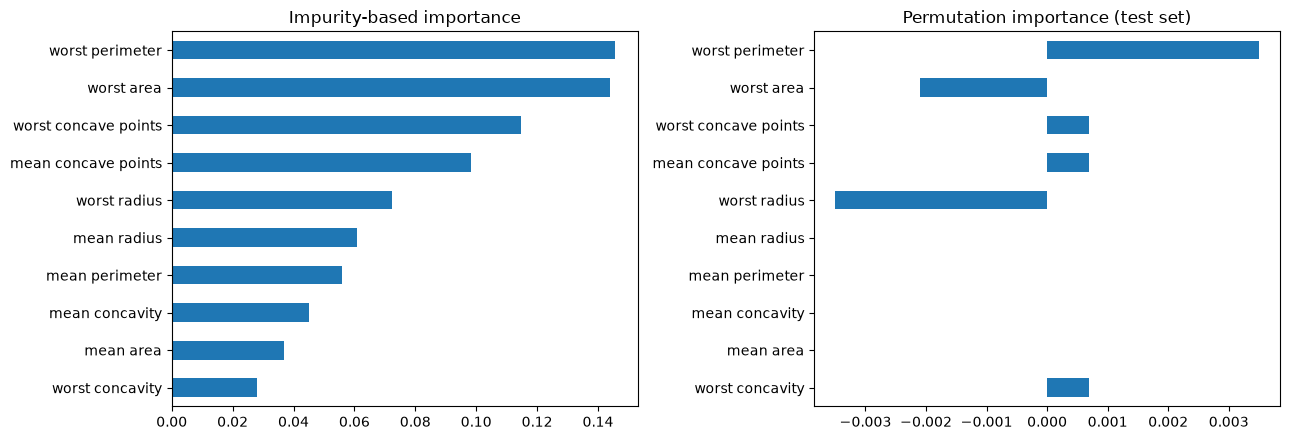

In [7]:
rf = models['Random Forest']
impurity_imp = pd.Series(rf.feature_importances_, index=feature_names)

perm = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=42)
perm_imp = pd.Series(perm.importances_mean, index=feature_names)

top = impurity_imp.sort_values(ascending=False).head(10).index
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
impurity_imp[top][::-1].plot.barh(ax=axes[0], title='Impurity-based importance')
perm_imp[top][::-1].plot.barh(ax=axes[1], title='Permutation importance (test set)')
plt.tight_layout()
plt.show()

Both methods agree that a small group of features (such as the "worst" size and concavity measurements) drive most of the predictions. The rankings are not identical: permutation importance, measured on unseen data, shows that some features with high impurity importance add little once correlated features are present.

## 5. Boosting

**Boosting** builds trees **sequentially**, where each new tree focuses on the mistakes of the previous ones. Boosting mainly reduces **bias**, using many shallow trees.

- **AdaBoost**: increases the weights of misclassified samples so the next model focuses on them. The final prediction is a weighted vote.
- **Gradient Boosting**: each new tree fits the **residual errors** (the gradient of the loss) of the current ensemble:

$$F_m(\mathbf{x}) = F_{m-1}(\mathbf{x}) + \eta \, h_m(\mathbf{x})$$

where $h_m$ is the new tree and $\eta$ is the **learning rate**. A smaller learning rate needs more trees but usually generalizes better.
- **HistGradientBoosting**: a much faster gradient boosting that bins feature values into histograms, handles missing values natively, and scales to large datasets.

In [8]:
boosters = {
    'AdaBoost': AdaBoostClassifier(n_estimators=200, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=200, learning_rate=0.1,
                                                    max_depth=3, random_state=42),
    'HistGradientBoosting': HistGradientBoostingClassifier(random_state=42),
}
for name, m in boosters.items():
    cv = cross_val_score(m, X_train, y_train, cv=5).mean()
    m.fit(X_train, y_train)
    print(f'{name:>21}: CV acc = {cv:.3f}, test acc = {m.score(X_test, y_test):.3f}')

             AdaBoost: CV acc = 0.967, test acc = 0.972
    Gradient Boosting: CV acc = 0.960, test acc = 0.958
 HistGradientBoosting: CV acc = 0.962, test acc = 0.972


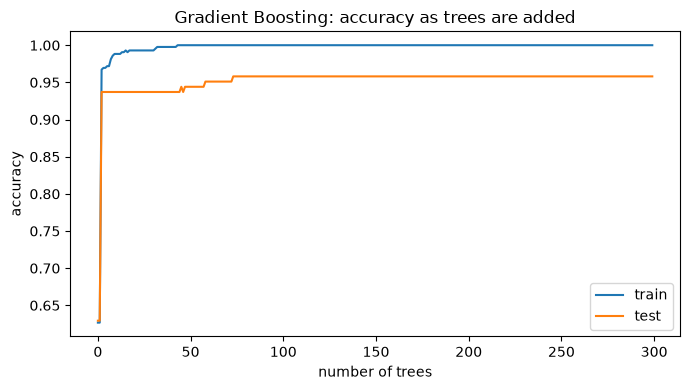

In [9]:
gb = GradientBoostingClassifier(n_estimators=300, learning_rate=0.1, max_depth=3,
                                random_state=42).fit(X_train, y_train)
test_scores = [np.mean(pred == y_test) for pred in gb.staged_predict(X_test)]
train_scores = [np.mean(pred == y_train) for pred in gb.staged_predict(X_train)]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(train_scores, label='train')
ax.plot(test_scores, label='test')
ax.set_xlabel('number of trees')
ax.set_ylabel('accuracy')
ax.set_title('Gradient Boosting: accuracy as trees are added')
ax.legend()
plt.tight_layout()
plt.show()

All boosting methods reach high accuracy. The staged plot shows how gradient boosting improves as trees are added: training accuracy quickly reaches 100%, while test accuracy levels off. In practice, the number of trees is controlled with early stopping or cross-validation to avoid overfitting.

## 6. Combining Different Models: Voting and Stacking

Ensembles can also combine **different types** of models:
- **Voting**: each model votes; **hard** voting uses predicted classes, **soft** voting averages predicted probabilities.
- **Stacking**: a **meta-model** (often logistic regression) learns how to best combine the base models' predictions, using cross-validated predictions to avoid leakage.

In [10]:
base_models = [
    ('lr', make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
    ('svc', make_pipeline(StandardScaler(), SVC(probability=True, random_state=42))),
    ('rf', RandomForestClassifier(n_estimators=200, random_state=42)),
]

voting = VotingClassifier(base_models, voting='soft')
stacking = StackingClassifier(base_models, final_estimator=LogisticRegression(), cv=5)

for name, m in [('Soft voting', voting), ('Stacking', stacking)]:
    m.fit(X_train, y_train)
    print(f'{name:>12}: test acc = {m.score(X_test, y_test):.3f}')

 Soft voting: test acc = 0.979
    Stacking: test acc = 0.979


Combining logistic regression, an SVM, and a random forest gives accuracy at least as good as the best single model, because the models make different kinds of errors that partly cancel out. Stacking adds a learned combination step, which can help when the base models have complementary strengths.

## Chapter Summary

- **Decision trees** split data with simple rules based on Gini or entropy; they are interpretable and need no scaling, but overfit easily.
- Tree complexity is controlled with **pre-pruning** (`max_depth`, `min_samples_leaf`) or **cost-complexity pruning** (`ccp_alpha`).
- **Bagging** and **Random Forests** average many diverse trees to reduce variance; the **OOB score** gives a free performance estimate. **Extra Trees** add more randomness for speed and diversity.
- **Feature importance** can be measured from impurity (fast) or by **permutation** on test data (more reliable).
- **Boosting** (AdaBoost, Gradient Boosting, HistGradientBoosting) builds trees sequentially to correct previous errors; the learning rate and number of trees must be balanced.
- **Voting** and **Stacking** combine different model types for more robust predictions.